In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('PS_20174392719_1491204439457_log.csv')
print("Shape:", df.shape)
print(df.columns)
df.head()

Shape: (859186, 11)
Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1.0,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1.0,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0.0,0.0


# Financial Transaction Risk & Fraud Pattern Analysis
This project analyses the PaySim dataset (Synthetic Financial Datasets For Fraud Detection) from Kaggle. The dataset is synthetic and was created using a simulator based on real mobile money transactions. The results show patterns in simulated transactions, not real bank transactions. The dataset contains 11 columns, including transaction type, amount, origin and destination account balances before and after each transaction, and a fraud label (isFraud). The analysis uses Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.
The analysis focuses on 6 questions:
1. How does the fraud rate differ across transaction types?
2. How do transaction amounts differ between fraudulent and normal transactions?
3. What do the origin and destination account balances show?
4. Are very large transactions disproportionately fraudulent?
5. Can simple rules identify fraud?
6. How does a rule-based approach compare with a basic machine learning model?

# Data check

In [77]:
print("Shape:", df.shape)
df.info()

Shape: (859186, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 859186 entries, 0 to 859185
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            859186 non-null  int64  
 1   type            859186 non-null  object 
 2   amount          859186 non-null  float64
 3   nameOrig        859186 non-null  object 
 4   oldbalanceOrg   859186 non-null  float64
 5   newbalanceOrig  859186 non-null  float64
 6   nameDest        859186 non-null  object 
 7   oldbalanceDest  859186 non-null  float64
 8   newbalanceDest  859186 non-null  float64
 9   isFraud         859185 non-null  float64
 10  isFlaggedFraud  859185 non-null  float64
dtypes: float64(7), int64(1), object(3)
memory usage: 72.1+ MB


In [78]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 2
Duplicate rows: 0


In [79]:
print(df["isFraud"].value_counts())
print()
print(df["isFraud"].value_counts(normalize=True)*100)

isFraud
0.0    858701
1.0       484
Name: count, dtype: int64

isFraud
0.0    99.943668
1.0     0.056332
Name: proportion, dtype: float64


There are no duplicate rows in the dataset. One row had missing values in the isFraud and isFlaggedFraud columns. Only 484 of the 859,185 transactions are fraudulent, or about one in 1,774. This creates a strong imbalance between normal and fraudulent transactions. If a model predicted every transaction as normal, it would still achieve 99.94% accuracy without detecting a single fraud case. For this reason, accuracy alone is not a useful measure of model performance in this analysis.

# Fraud Rate by Transaction Type

In [80]:
fraud_by_type = df.groupby("type")["isFraud"].agg(["count", "sum", "mean"])
fraud_by_type["mean"] = fraud_by_type["mean"] * 100
fraud_by_type = fraud_by_type.rename(columns={"count": "transactions", "sum": "fraud_cases", "mean": "fraud_rate_%"})
fraud_by_type

,transactions,fraud_cases,fraud_rate_%
type,,,
CASH_IN,188098,0.0,0.000000
CASH_OUT,310537,250.0,0.080506
DEBIT,5686,0.0,0.000000
PAYMENT,283759,0.0,0.000000
TRANSFER,71105,234.0,0.329091


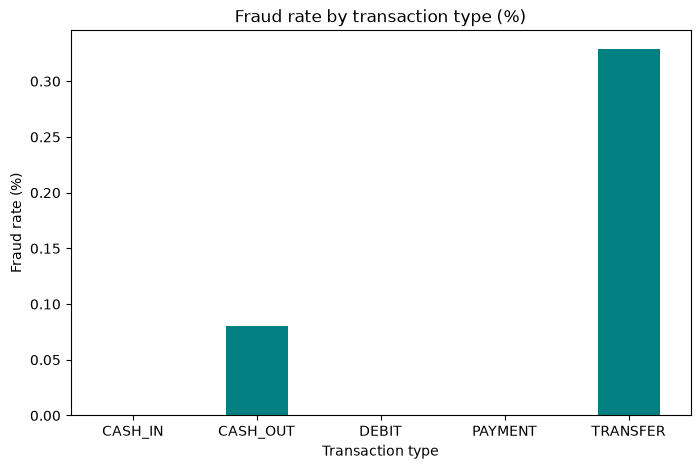

In [81]:
fraud_by_type["fraud_rate_%"].plot(kind="bar", figsize=(8, 5), color="teal")
plt.title("Fraud rate by transaction type (%)")
plt.xlabel("Transaction type")
plt.ylabel("Fraud rate (%)")
plt.xticks(rotation=0)
plt.show()

In [82]:
print(fraud_by_type[["fraud_rate_%"]].round(3).to_string())

          fraud_rate_%
type                  
CASH_IN          0.000
CASH_OUT         0.081
DEBIT            0.000
PAYMENT          0.000
TRANSFER         0.329


Fraud occurs in only two transaction types: TRANSFER (234 cases) and CASH_OUT (250 cases). The fraud rate is higher for TRANSFER (0.329%) than for CASH_OUT (0.081%), almost four times higher. No fraud was found in CASH_IN, DEBIT or PAYMENT transactions. TRANSFER and CASH_OUT make up about 44% of all transactions but 100% of fraud, so transaction type is a first filter for fraud rules.

# Transaction Amounts, Fraud vs Normal

In [83]:
import numpy as np

In [84]:
fraud_df = df[df["isFraud"] == 1]
normal_df = df[df["isFraud"] == 0]
plot_df = pd.concat([fraud_df, normal_df.sample(100000, random_state=42)])

In [85]:
plot_df = df.copy()

In [86]:
df.groupby("isFraud")["amount"].agg(["count", "mean", "median", "max"])

,count,mean,median,max
isFraud,,,,
0.0,858701,163244.099977,80679.50,6419835.27
1.0,484,958745.013698,235375.43,10000000.00


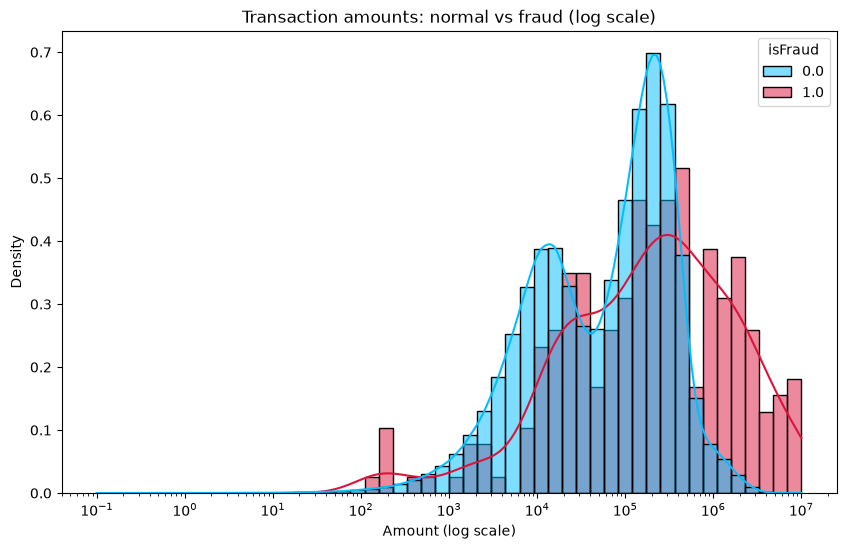

In [87]:
plt.figure(figsize=(10, 6))
sns.histplot(data=plot_df[plot_df["amount"]>0], x="amount", hue="isFraud",
             log_scale=True, bins=50, stat="density", common_norm=False,
             palette=["deepskyblue", "crimson"], kde=True)
plt.title("Transaction amounts: normal vs fraud (log scale)")
plt.xlabel("Amount (log scale)")
plt.ylabel("Density")
plt.show()

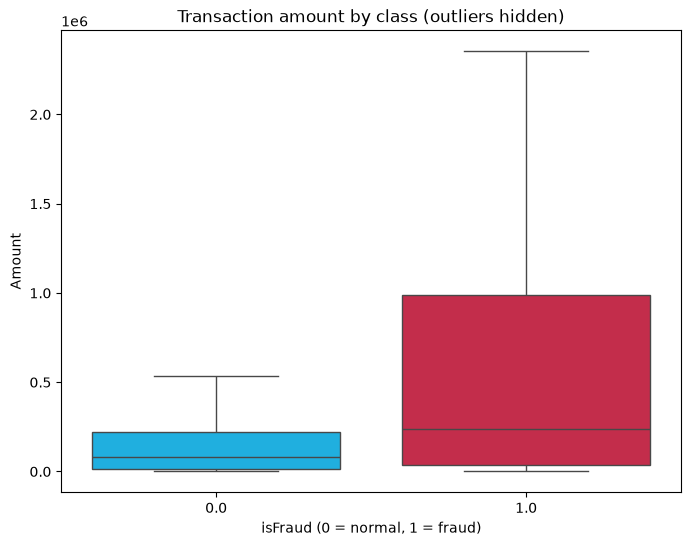

In [88]:
plt.figure(figsize=(8, 6))
sns.boxplot(
    data=plot_df,
    x="isFraud",
    y="amount",
    hue="isFraud",
    showfliers=False,
    palette=["deepskyblue", "crimson"],
    legend=False
)
plt.title("Transaction amount by class (outliers hidden)")
plt.xlabel("isFraud (0 = normal, 1 = fraud)")
plt.ylabel("Amount")
plt.show()

In [89]:
df.groupby("isFraud")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0.0,858701.0,163244.099977,2.605138e+05,0.1,13028.5500,80679.50,220994.3400,6419835.27
1.0,484.0,958745.013698,1.866736e+06,119.0,34630.9375,235375.43,987484.9825,10000000.00


The middle 50% of fraudulent amounts ranges from around 30,000 to 1,000,000, while for normal transactions it ranges from around 10,000 to 215,000. This shows that fraudulent amounts vary much more. The upper whisker of normal transactions (about 530,000) is still within the middle 50% of fraudulent amounts.

# Origin and Destination Balances

In [90]:
df.groupby("isFraud")[["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]].median()

,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
isFraud,,,,
0.0,16182.000,0.0,130275.0,229652.020
1.0,213794.595,0.0,0.0,18799.475


In [91]:
df["OriginEmptied"] = (df["oldbalanceOrg"]>0) & (df["newbalanceOrig"] == 0)
emptied = df.groupby("OriginEmptied")["isFraud"].agg(["count", "sum", "mean"])
emptied["mean"] = emptied["mean"]*100
emptied

,count,sum,mean
OriginEmptied,,,
False,660047,23.0,0.003485
True,199138,461.0,0.231498


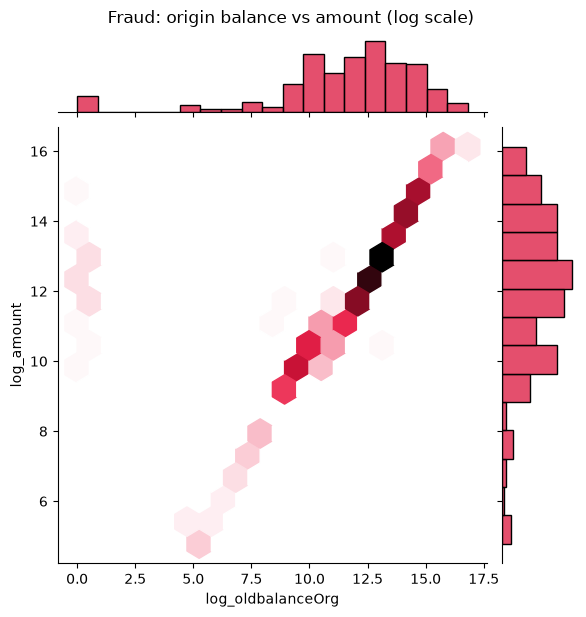

In [92]:
fraud_plot = fraud_df.copy()
fraud_plot["log_amount"] = np.log1p(fraud_plot["amount"])
fraud_plot["log_oldbalanceOrg"] = np.log1p(fraud_plot["oldbalanceOrg"])
sns.jointplot(x="log_oldbalanceOrg", y="log_amount", data=fraud_plot,
              kind="hex", color="crimson")
plt.suptitle("Fraud: origin balance vs amount (log scale)", y=1.02)
plt.show()

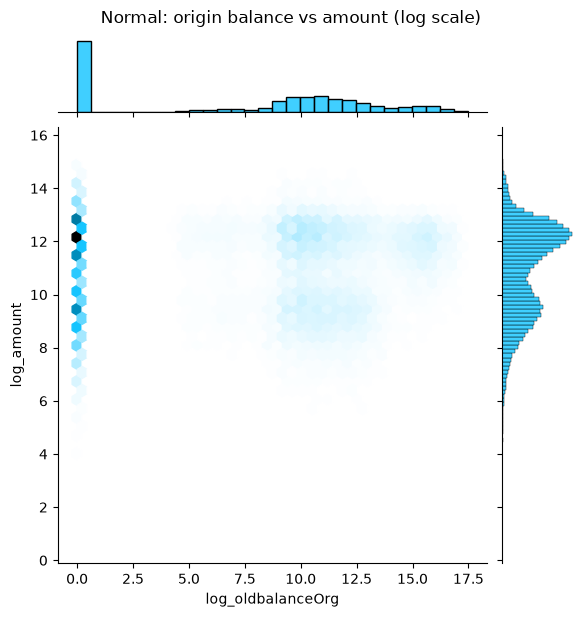

In [93]:
normal_plot = normal_df.sample(50000, random_state=42).copy()
normal_plot["log_amount"] = np.log1p(normal_plot["amount"])
normal_plot["log_oldbalanceOrg"] = np.log1p(normal_plot["oldbalanceOrg"])
sns.jointplot(x="log_oldbalanceOrg", y="log_amount", data=normal_plot,
              kind="hex", color="deepskyblue")
plt.suptitle("Normal: origin balance vs amount (log scale)", y=1.02)
plt.show()

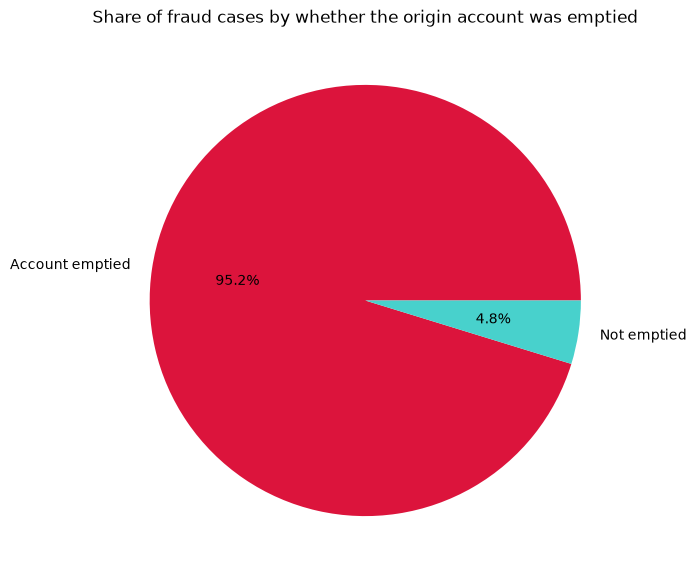

In [94]:
emptied_share = df[df["isFraud"] == 1]["OriginEmptied"].value_counts()
labels = ["Account emptied" if x else "Not emptied" for x in emptied_share.index]
plt.figure(figsize=(7, 7))
plt.pie(emptied_share.values, labels=labels, autopct="%1.1f%%",
        colors=["crimson", "mediumturquoise"])
plt.title("Share of fraud cases by whether the origin account was emptied")
plt.show()

Fraudulent transactions usually start with higher origin balances (median 213,794.60 vs 16,182.00). In most fraud cases, the transaction takes almost the entire balance. The hexbin plot shows this pattern, with the amount close to the origin balance. In 95.2% fraud cases the origin account was left empty. The fraud rate is higher for emptied accounts (0.231% vs 0.003%), but this alone is not enough to identify fraud, since 199,138 transactions emptied the account and only 461 were fraudulent. In at least half of fraud cases the destination account was empty before the transaction (median 0 vs 130,275.00 for normal ones).

# Very Large Transactions

In [95]:
threshold = df["amount"].quantile(0.99)
big = df[df["amount"] > threshold]
print("Threshold (top 1% of amounts):", round(threshold, 2))
print("Number of largest transactions:", len(big))
print("Of which fraudulent:", big["isFraud"].sum())
print("Fraud rate among the largest transactions (%):", round(big["isFraud"].mean()*100, 3))
print("Fraud rate overall (%):", round(df["isFraud"].mean()*100, 3))
print("Share of all fraud above the threshold (%):", round(big["isFraud"].sum() / df["isFraud"].sum()*100, 1))

Threshold (top 1% of amounts): 1341777.27
Number of largest transactions: 8592
Of which fraudulent: 91.0
Fraud rate among the largest transactions (%): 1.059
Fraud rate overall (%): 0.056
Share of all fraud above the threshold (%): 18.8


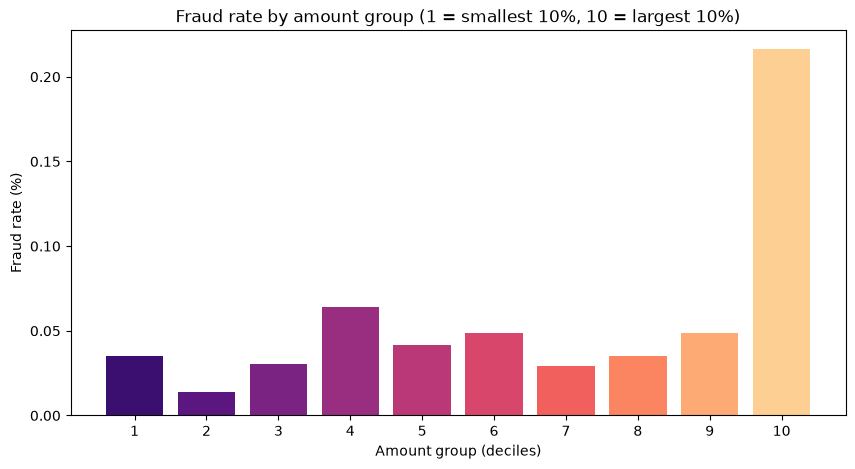

In [96]:
df["AmountDecile"] = pd.qcut(df["amount"], 10, labels=False, duplicates="drop")+1
fraud_by_decile = df.groupby("AmountDecile")["isFraud"].mean()*100
colors = plt.cm.magma(np.linspace(0.2, 0.9, len(fraud_by_decile)))
plt.figure(figsize=(10, 5))
plt.bar(fraud_by_decile.index, fraud_by_decile.values, color=colors)
plt.title("Fraud rate by amount group (1 = smallest 10%, 10 = largest 10%)")
plt.xlabel("Amount group (deciles)")
plt.ylabel("Fraud rate (%)")
plt.xticks(fraud_by_decile.index)
plt.show()

In [97]:
print(df["isFlaggedFraud"].value_counts())
print("Fraud cases among flagged:", df[df["isFlaggedFraud"] == 1]["isFraud"].sum())
print("Fraud cases in total:", df["isFraud"].sum())

isFlaggedFraud
0.0    859185
Name: count, dtype: int64
Fraud cases among flagged: 0.0
Fraud cases in total: 484.0


The top 1% of amounts (above 1,341,777.27) contains 91 fraud cases. The fraud rate in this group is 1.059%, compared with 0.056% across the full dataset. So very large transactions are about 19 times more likely to be fraudulent. However, only the largest of the ten amount groups has a higher fraud rate. These 91 cases account for just 18.8% of all fraud, so transaction amount alone cannot catch most fraud cases. The dataset's isFlaggedFraud column is also not useful, as it has a value of 0 for every transaction, including all 484 fraud cases.

# Simple Rule-Based Fraud Indicators

In [98]:
df["Rule1_RiskyType"] = df["type"].isin(["TRANSFER", "CASH_OUT"])
df["Rule2_AccountEmptied"] = df["OriginEmptied"]
df["Rule3_LargeAmount"] = df["amount"]>threshold
rule_columns = ["Rule1_RiskyType", "Rule2_AccountEmptied", "Rule3_LargeAmount"]
df["RulesTriggered"] = df[rule_columns].sum(axis=1)
print(df["RulesTriggered"].value_counts().sort_index())

RulesTriggered
0    438898
1    256145
2    159200
3      4943
Name: count, dtype: int64


In [99]:
total_fraud = df["isFraud"].sum()
results = []
for n in [1, 2, 3]:
    flagged = df["RulesTriggered"] >= n
    caught = (flagged & (df["isFraud"] == 1)).sum()
    results.append({
        "Rules required": f"{n}+",
        "Flagged transactions": flagged.sum(),
        "Fraud detected": caught,
        "Precision (%)": round(caught / flagged.sum()*100, 2),
        "Recall (%)": round(caught / total_fraud*100, 1)
    })
results_df = pd.DataFrame(results)
display(results_df)

,Rules required,Flagged transactions,Fraud detected,Precision (%),Recall (%)
0,1+,420288,484,0.12,100.0
1,2+,164143,465,0.28,96.1
2,3+,4943,87,1.76,18.0


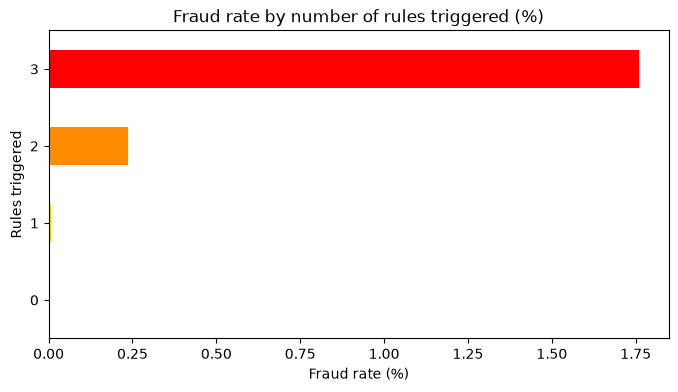

In [100]:
fraud_by_rules = df.groupby("RulesTriggered")["isFraud"].mean()*100
bar_colors = ["yellowgreen", "gold", "darkorange", "red"][:len(fraud_by_rules)]
fraud_by_rules.plot(kind="barh", figsize=(8, 4), color=bar_colors)
plt.title("Fraud rate by number of rules triggered (%)")
plt.xlabel("Fraud rate (%)")
plt.ylabel("Rules triggered")
plt.show()

The fraud rate increases with the number of rules triggered: 1.76% for three rules and about 0.24% for two, compared with 0.056% overall. Requiring two rules finds 465 of 484 fraud cases (96.1%),but it also flags 164,143 transactions, around 19% of the dataset. The 100% recall with one rule is expected, since all fraud cases fall within the two transaction types selected for Rule 1. Also, the thresholds were chosen using the same data on which the rules were tested, so the results may be better than they would be on new data.

# Rule-Based vs Basic Machine Learning

In [101]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, average_precision_score, precision_score, recall_score

In [102]:
print(df["isFraud"].isna().sum())
print(df["isFraud"].value_counts(dropna=False))

1
isFraud
0.0    858701
1.0       484
NaN         1
Name: count, dtype: int64


In [103]:
df_ml = df.dropna(subset=["isFraud"]).sample(500000, random_state=42)
X = pd.get_dummies(df_ml[["type", "amount"]], columns=["type"])
y = df_ml["isFraud"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("PR-AUC:", average_precision_score(y_test, y_prob))

[[99841   103]
 [   47     9]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     99944
           1       0.08      0.16      0.11        56

    accuracy                           1.00    100000
   macro avg       0.54      0.58      0.55    100000
weighted avg       1.00      1.00      1.00    100000

PR-AUC: 0.029383920867445876


In [104]:
rule_pred = (df_ml.loc[X_test.index, "RulesTriggered"] >= 2).astype(int)
print(confusion_matrix(y_test, rule_pred))
print(classification_report(y_test, rule_pred))

[[81179 18765]
 [    2    54]]
              precision    recall  f1-score   support

           0       1.00      0.81      0.90     99944
           1       0.00      0.96      0.01        56

    accuracy                           0.81    100000
   macro avg       0.50      0.89      0.45    100000
weighted avg       1.00      0.81      0.90    100000



In [105]:
comparison = pd.DataFrame({
    "Model": ["Rule-based (2+ rules)", "Random Forest"],
    "Precision": [precision_score(y_test, rule_pred), precision_score(y_test, y_pred)],
    "Recall": [recall_score(y_test, rule_pred), recall_score(y_test, y_pred)]
}).round(3)
comparison

,Model,Precision,Recall
0,Rule-based (2+ rules),0.003,0.964
1,Random Forest,0.080,0.161


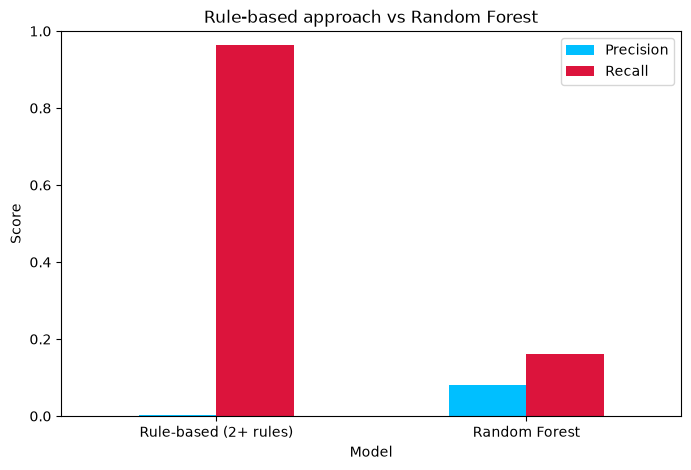

In [106]:
comparison.set_index("Model").plot(kind="bar", figsize=(8, 5),
                                   color=["deepskyblue", "crimson"])
plt.title("Rule-based approach vs Random Forest")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

On the test set (56 fraud cases among 100,000 transactions), the rules find 54 cases (recall 0.96) but also produce 18,765 false alarms. This means that only 0.3% of flagged transactions are actual fraud, or around 350 false alarms for each detected fraud.  Random Forest, which uses only transaction type and amount, detects 9 fraud cases (recall 0.16) and produces 103 false alarms (precision 0.08). Its PR-AUC is 0.029, which is low. The comparison is not fairbecause the rules also use account balance information, which was not included in the model. There are also only 56 fraud cases in the test set, so the model results are unstable.

# Conclusion
## Key findings
1. Fraud is rare (484 of 859,186 transactions) and appears only in TRANSFER (0.329%) and CASH_OUT (0.081%). The other three types, which make up around 56% of all transactions, contain no fraud.
2. Fraudulent transactions have higher amounts (median 235,375.43 vs 80,679.50), but the two groups overlap, so transaction amount is a weak filter on its own.
3. The strongest pattern is an emptied origin account (95.2% of fraud cases), but it also describes 199,138 transactions, most of which are normal.
4. Very large transactions have a higher fraud rate (1.059% vs 0.056%), but account for only 18.8% of all fraud cases.
5. The best simple rule combination (two or more rules) finds 96.1% of fraud cases, but also flags about 19% of all transactions. This would create too many alerts and will not be workable in practice.
6. Neither approach gives good results overall. The rules detect most fraud cases but produce too many false alarms, while the model produces fewer false alarms but misses most fraud.
Overall, the analysis shows some clear patterns linked to fraud in this simulated dataset. However, these results are not enough to build a reliable fraud detection system.
## Limitations
* The data is synthetic, so some patterns such as emptied accounts may reflect how it was simulated rather than real fraud behaviour.
* The balance columns may be unreliable for fraud detection (according to the dataset description), and the strongest signal depends on them.
* The rules and their thresholds were chosen after examining the same data used to test them. This may make their results look better than they would on new data.
* he dataset contains only 484 fraud cases, including 56 in the test set. The model uses only two features, was not tuned and was tested on a single split.
